# VisionGuard AI – System Evaluation

## Objective
This evaluation examines the performance of the VisionGuard AI prototype in detecting people, tracking objects across video frames, and identifying potential surveillance events.

## Evaluation Components
- Person detection using YOLO11n
- Multi-object tracking using ByteTrack
- Restricted-zone intrusion detection
- Loitering event detection
- Event logging and dashboard visualization

## Evaluation Approach
The system is evaluated using video-based functional testing, event-log inspection, and qualitative observations. Quantitative accuracy metrics are only calculated when manually verified ground-truth labels are available.

In [3]:
import cv2
import os
import sys
import pandas as pd
from pathlib import Path

# Locate the project root
cwd = Path.cwd()

if (cwd / "database").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "database").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError("Could not locate the project root.")

# Add project root to Python's import path
sys.path.insert(0, str(PROJECT_ROOT))

from database.db_manager import get_events

VIDEO_PATH = PROJECT_ROOT / "outputs" / "processed_videos" / "visionguard_browser.mp4"

cap = cv2.VideoCapture(str(VIDEO_PATH))

if cap.isOpened():
    fps = cap.get(cv2.CAP_PROP_FPS)
    frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    duration = frames / fps if fps else 0

    video_info = pd.DataFrame([{
        "FPS": round(fps, 2),
        "Total Frames": frames,
        "Width": width,
        "Height": height,
        "Duration (seconds)": round(duration, 2)
    }])

    display(video_info)
else:
    print("Video could not be opened.")

cap.release()

,FPS,Total Frames,Width,Height,Duration (seconds)
0,30.0,924,1280,720,30.8


In [4]:
events = get_events()

if events:
    df = pd.DataFrame(
        events,
        columns=["ID", "Event Type", "Object ID", "Timestamp", "Details"]
    )

    display(df)

    print("Event Summary:")
    display(df["Event Type"].value_counts().to_frame("Count"))
else:
    print("No events found in the database.")

,ID,Event Type,Object ID,Timestamp,Details
0,27,Restricted Zone Intrusion,500,30.60,Person entered restricted area
1,26,Restricted Zone Intrusion,483,30.50,Person entered restricted area
2,25,Loitering,293,25.37,Person remained in monitored video
3,24,Restricted Zone Intrusion,411,23.93,Person entered restricted area
4,23,Restricted Zone Intrusion,381,23.33,Person entered restricted area
5,22,Restricted Zone Intrusion,264,14.57,Person entered restricted area
6,21,Restricted Zone Intrusion,224,11.87,Person entered restricted area
7,20,Restricted Zone Intrusion,61,10.50,Person entered restricted area
8,19,Restricted Zone Intrusion,159,9.80,Person entered restricted area
9,18,Restricted Zone Intrusion,57,5.77,Person entered restricted area


Event Summary:


,Count
Event Type,
Restricted Zone Intrusion,10
Loitering,1


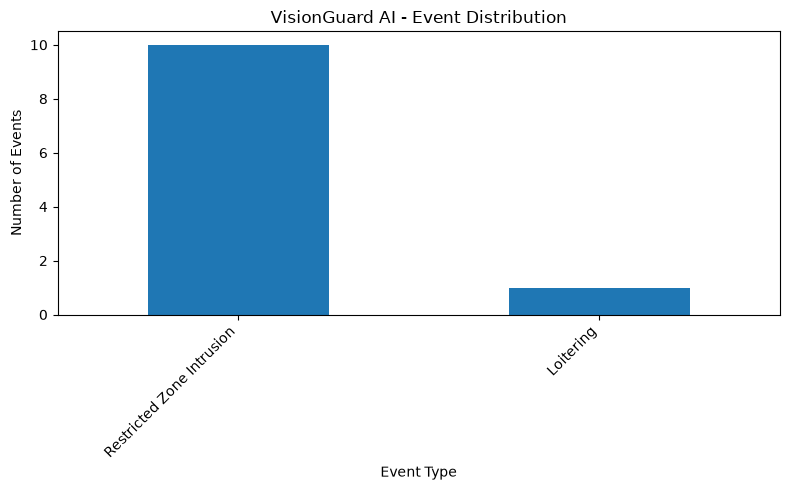

In [5]:
import matplotlib.pyplot as plt

event_counts = df["Event Type"].value_counts()

plt.figure(figsize=(8, 5))
event_counts.plot(kind="bar")
plt.title("VisionGuard AI - Event Distribution")
plt.xlabel("Event Type")
plt.ylabel("Number of Events")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [8]:
import cv2
import os

VIDEO_PATH = os.path.abspath("../outputs/processed_videos/visionguard_output.mp4")

print("Checking:", VIDEO_PATH)
print("File exists:", os.path.exists(VIDEO_PATH))

cap = cv2.VideoCapture(VIDEO_PATH)

if cap.isOpened():
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = cap.get(cv2.CAP_PROP_FRAME_COUNT)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    duration = total_frames / fps if fps > 0 else 0

    print("\n===== VIDEO PERFORMANCE DETAILS =====")
    print("FPS:", fps)
    print("Total Frames:", int(total_frames))
    print("Resolution:", width, "x", height)
    print("Duration:", round(duration, 2), "seconds")
    print("Video readable: Yes")
else:
    print("Video could not be opened.")

cap.release()

Checking: d:\Real Object Detection\outputs\processed_videos\visionguard_output.mp4
File exists: True

===== VIDEO PERFORMANCE DETAILS =====
FPS: 30.0
Total Frames: 924
Resolution: 1280 x 720
Duration: 30.8 seconds
Video readable: Yes


## Functional Test Observations

| Test | Expected Functionality | Observation |
|---|---|---|
| Person Detection | Detect persons in video frames | Bounding boxes were displayed around detected persons in the processed video. |
| Object Tracking | Assign tracking IDs to detected persons | Tracking IDs were visible across processed frames. |
| Restricted-Zone Detection | Detect entry into a configured zone | Restricted-zone events were recorded in the event database during testing. |
| Loitering Detection | Generate a potential loitering event | A loitering event was recorded during the test run. |
| Event Logging | Store event type, ID, timestamp and details | Events were displayed in the Streamlit dashboard. |
| Dashboard | Display event statistics and logs | Metrics, event table and analytics chart were displayed. |
| Video Visualization | Display processed video | Converted processed video played successfully in the Streamlit dashboard. |

These observations represent functional testing of the prototype and are not equivalent to a formally measured detection accuracy.

## Limitations of Evaluation

- The evaluation was conducted on a limited number of test videos.
- No large-scale manually annotated benchmark dataset was used.
- Detection accuracy, precision, recall and F1-score have not yet been established.
- Tracking IDs may change or be lost under occlusion or detection failure.
- The current loitering implementation is a prototype and does not reliably distinguish stationary behavior from continued movement.
- Unattended-object detection requires further validation across multiple scenarios.

## Conclusion

The prototype demonstrates the integration of YOLO11n-based object detection, ByteTrack-based tracking, rule-based event detection, database logging, and dashboard visualization. Further testing with annotated datasets is required to establish quantitative performance and improve event detection reliability.